<a href="https://colab.research.google.com/github/nomi181472/instance-segmentation-models-and-notebooks/blob/main/07_EdgeTAM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 7/7 · EdgeTAM (promptable, on-device SAM-2 style)
Meta's EdgeTAM image segmenter (RepViT-based encoder, SAM-2 decoder with high-res skip features). Promptable: it returns an instance-level mask per prompt (here 4 point prompts per image) but is **not class-aware**. Encoder and decoder are exported separately for every backend.

**What this notebook does:** native inference → export to **ONNX**, **LiteRT (.tflite)**, **NCNN** → run all four backends on the same images → side-by-side grid → everything zipped (auto-download at the end).

**Runtime:** Colab, CPU is fine (GPU optional). Everything runs on CPU for a fair comparison.
Each stage is wrapped in `try/except`: if one exporter fails on this model, the notebook keeps going, marks that column FAILED in the grid and still produces the zip.

> If a `pip install` cell says it replaced packages (numpy/torch), use **Runtime → Restart session** once, then **Run all** again.

In [ ]:
# 1) Install (≈2-4 min)
!pip -q install onnx onnxruntime onnxscript pnnx ncnn ai-edge-litert litert-torch opencv-python-headless matplotlib hydra-core iopath tqdm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.2/42.2 kB 2.0 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 48.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 39.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 754.2/754.2 kB 23.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 28.8/28.8 MB 22.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.4/8.4 MB 58.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 807.3/807.3 kB 26.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 459.5/459.5 kB 18.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.3/21.3 MB 44.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.8/69.8 MB 10.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 51.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 168.8/168.8 kB 10.3 MB/s eta 0:00:00
   ━━━━━

In [ ]:
%%writefile /content/seg_common.py
"""Shared helpers for the 7 instance-segmentation export notebooks.
Pipeline per notebook: PyTorch/native inference -> ONNX -> LiteRT -> NCNN -> comparison grid -> zip.
Every stage is wrapped so one failing exporter never aborts the notebook."""
import os, sys, time, json, shutil, subprocess, traceback, urllib.request, zipfile, glob
from pathlib import Path
import numpy as np, cv2
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

ROOT = Path("/content") if Path("/content").exists() else Path.cwd()
OUT = ROOT / "outputs"; MODELS = OUT / "models"; RES = OUT / "results"; SAMPLES = ROOT / "samples"
for d in (OUT, MODELS, RES, SAMPLES): d.mkdir(parents=True, exist_ok=True)

RESULTS, STATUS, RAW, SAMPLE_IMGS = {}, {}, {}, {}
REF = "PyTorch"   # name of the reference backend (other backends are aligned/compared against it)     # backend -> {image: bgr} / status dict / first raw outputs

COCO80 = ("person bicycle car motorcycle airplane bus train truck boat traffic_light fire_hydrant stop_sign "
          "parking_meter bench bird cat dog horse sheep cow elephant bear zebra giraffe backpack umbrella handbag "
          "tie suitcase frisbee skis snowboard sports_ball kite baseball_bat baseball_glove skateboard surfboard "
          "tennis_racket bottle wine_glass cup fork knife spoon bowl banana apple sandwich orange broccoli carrot "
          "hot_dog pizza donut cake chair couch potted_plant bed dining_table toilet tv laptop mouse remote keyboard "
          "cell_phone microwave oven toaster sink refrigerator book clock vase scissors teddy_bear hair_drier "
          "toothbrush").split()
COCO80 = [n.replace("_", " ") for n in COCO80]
COCO91_TO_80 = [1,2,3,4,5,6,7,8,9,10,11,13,14,15,16,17,18,19,20,21,22,23,24,25,27,28,31,32,33,34,35,36,37,38,39,40,
                41,42,43,44,46,47,48,49,50,51,52,53,54,55,56,57,58,59,60,61,62,63,64,65,67,70,72,73,74,75,76,77,78,
                79,80,81,82,84,85,86,87,88,89,90]

SAMPLE_URLS = {
    "cats":   "http://images.cocodataset.org/val2017/000000039769.jpg",
    "bus":    "https://raw.githubusercontent.com/ultralytics/yolov5/master/data/images/bus.jpg",
    "zidane": "https://raw.githubusercontent.com/ultralytics/yolov5/master/data/images/zidane.jpg",
    "room":   "http://images.cocodataset.org/val2017/000000000139.jpg",
}

def load_samples(n=4):
    """Download sample images (or use any .jpg/.png you upload into /content/samples)."""
    for name, url in SAMPLE_URLS.items():
        p = SAMPLES / f"{name}.jpg"
        if not p.exists():
            try:
                req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
                p.write_bytes(urllib.request.urlopen(req, timeout=30).read())
            except Exception as e:
                print(f"[samples] could not download {name}: {e}")
    files = sorted([*SAMPLES.glob("*.jpg"), *SAMPLES.glob("*.png"), *SAMPLES.glob("*.jpeg")])[:n]
    if not files:
        raise RuntimeError("No sample images. Upload some .jpg files to /content/samples and rerun this cell.")
    out = [(f.stem, cv2.imread(str(f))) for f in files]
    out = [(k, v) for k, v in out if v is not None]
    SAMPLE_IMGS.update(dict(out)); return out

# ------------------------------------------------------------------ math / image utils
def sigmoid(x): return 1.0 / (1.0 + np.exp(-np.clip(x, -60, 60)))
def softmax(x, axis=-1):
    e = np.exp(x - x.max(axis=axis, keepdims=True)); return e / e.sum(axis=axis, keepdims=True)

def nms_xyxy(boxes, scores, iou=0.5, classes=None, max_det=100):
    """Numpy NMS (class-aware if classes given). Returns kept indices."""
    if len(boxes) == 0: return np.zeros((0,), dtype=np.int64)
    b = boxes.astype(np.float32).copy()
    if classes is not None: b += (np.asarray(classes, np.float32) * (b.max() + 1))[:, None]
    x1, y1, x2, y2 = b.T; areas = np.maximum(0, x2 - x1) * np.maximum(0, y2 - y1)
    order = np.argsort(-scores); keep = []
    while order.size and len(keep) < max_det:
        i = order[0]; keep.append(i)
        xx1 = np.maximum(x1[i], x1[order[1:]]); yy1 = np.maximum(y1[i], y1[order[1:]])
        xx2 = np.minimum(x2[i], x2[order[1:]]); yy2 = np.minimum(y2[i], y2[order[1:]])
        inter = np.maximum(0, xx2 - xx1) * np.maximum(0, yy2 - yy1)
        order = order[1:][inter / (areas[i] + areas[order[1:]] - inter + 1e-9) <= iou]
    return np.array(keep, dtype=np.int64)

def letterbox_tl(img, size_hw, pad=114):
    """Keep-ratio resize, pad bottom/right (mmdet style). Returns padded, scale, (new_h,new_w)."""
    H, W = img.shape[:2]; th, tw = size_hw; s = min(th / H, tw / W)
    nh, nw = int(round(H * s)), int(round(W * s))
    r = cv2.resize(img, (nw, nh), interpolation=cv2.INTER_LINEAR)
    canvas = np.full((th, tw, 3), pad, np.uint8); canvas[:nh, :nw] = r
    return canvas, s, (nh, nw)

def color_for(i):
    rng = np.random.RandomState(i * 7 + 3); return tuple(int(c) for c in rng.randint(60, 255, 3))

def mask_to_box(m):
    ys, xs = np.where(m)
    return np.array([xs.min(), ys.min(), xs.max(), ys.max()], np.float32) if len(xs) else np.zeros(4, np.float32)

def draw_instances(img, inst, alpha=0.5):
    """inst = dict(masks=(N,H,W) bool|None, boxes=(N,4)|None, labels=[str], scores=(N,))"""
    out = img.copy(); masks, boxes = inst.get("masks"), inst.get("boxes")
    labels, scores = inst.get("labels", []), inst.get("scores")
    n = len(labels) if labels is not None and len(labels) else (len(masks) if masks is not None else 0)
    for i in range(n):
        c = color_for(i)
        if masks is not None and i < len(masks):
            m = masks[i].astype(bool)
            if m.shape != out.shape[:2]: m = cv2.resize(m.astype(np.uint8), (out.shape[1], out.shape[0]), interpolation=cv2.INTER_NEAREST).astype(bool)
            out[m] = (out[m] * (1 - alpha) + np.array(c) * alpha).astype(np.uint8)
            cs, _ = cv2.findContours(m.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
            cv2.drawContours(out, cs, -1, c, 2)
        b = boxes[i] if boxes is not None and i < len(boxes) else (mask_to_box(masks[i]) if masks is not None else None)
        if b is not None and np.any(b):
            x1, y1, x2, y2 = [int(v) for v in b]; cv2.rectangle(out, (x1, y1), (x2, y2), c, 2)
            txt = (labels[i] if i < len(labels) else "") + (f" {scores[i]:.2f}" if scores is not None else "")
            if txt: cv2.putText(out, txt, (x1, max(12, y1 - 5)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 2); cv2.putText(out, txt, (x1, max(12, y1 - 5)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, c, 1)
    return out

# ------------------------------------------------------------------ output alignment (backends reorder / transpose outputs)
def _fit(r, g):
    if g.size != r.size: return None
    cands = [g.reshape(r.shape)] if g.shape != r.shape else [g]
    if g.ndim == 4 and r.ndim == 4 and g.transpose(0, 3, 1, 2).shape == r.shape: cands.append(g.transpose(0, 3, 1, 2))
    if g.ndim == 3 and r.ndim == 3 and g.transpose(0, 2, 1).shape == r.shape: cands.append(g.transpose(0, 2, 1))
    cands = [c for c in cands if c.shape == r.shape]
    if not cands: return None
    errs = [float(np.mean((c.astype(np.float64) - r) ** 2)) for c in cands]
    k = int(np.argmin(errs)); return cands[k], errs[k]

class Aligner:
    """Maps a backend's outputs onto the PyTorch reference order/layout (decided on the first call)."""
    def __init__(self, ref): self.ref, self.plan = ref, None
    def __call__(self, got):
        got = [np.asarray(g, np.float32) for g in got]
        if self.plan is None:
            used, plan = set(), []
            for r in self.ref:
                best = None
                for j, g in enumerate(got):
                    if j in used: continue
                    f = _fit(r, g)
                    if f and (best is None or f[1] < best[1]): best = (j, f[1], f[0].shape, g.shape)
                if best is None: raise RuntimeError(f"cannot align output {r.shape} with {[g.shape for g in got]}")
                used.add(best[0]); plan.append(best[0])
            self.plan = plan
        return [(_fit(r, got[j]) or (got[j],))[0] for r, j in zip(self.ref, self.plan)]

# ------------------------------------------------------------------ backends
def export_onnx(module, example_inputs, path, input_names, output_names, opset=17):
    import torch
    module.eval(); path = str(path)
    kw = dict(input_names=input_names, output_names=output_names, opset_version=opset, do_constant_folding=True)
    with torch.no_grad():
        try: torch.onnx.export(module, tuple(example_inputs), path, dynamo=False, **kw)
        except TypeError: torch.onnx.export(module, tuple(example_inputs), path, **kw)
    return path

def make_ort(path):
    import onnxruntime as ort
    so = ort.SessionOptions(); so.log_severity_level = 3
    s = ort.InferenceSession(str(path), so, providers=["CPUExecutionProvider"]); names = [i.name for i in s.get_inputs()]
    return lambda xs: s.run(None, {n: np.ascontiguousarray(x) for n, x in zip(names, xs)})

def export_litert(module, example_inputs, path):
    import litert_torch, torch
    module.eval()
    with torch.no_grad(): m = litert_torch.convert(module, tuple(example_inputs))
    m.export(str(path)); return str(path)

def export_litert_from_onnx(onnx_path, path, extra=""):
    """ONNX -> TFLite via onnx2tf (needs: pip install onnx2tf tensorflow tf_keras onnx_graphsurgeon sng4onnx onnxsim psutil)."""
    d = Path(path).parent / "_onnx2tf"; shutil.rmtree(d, ignore_errors=True)
    r = subprocess.run(f"onnx2tf -i {onnx_path} -o {d} {extra}", shell=True, capture_output=True, text=True)
    fs = sorted(d.glob("*_float32.tflite"))
    if not fs: raise RuntimeError("onnx2tf produced no tflite:\n" + (r.stdout + r.stderr)[-1500:])
    shutil.copy(fs[0], path); shutil.rmtree(d, ignore_errors=True); return str(path)

def _litert_direct(path):
    from ai_edge_litert.interpreter import Interpreter
    it = Interpreter(model_path=str(path)); it.allocate_tensors()
    ins, outs = it.get_input_details(), it.get_output_details()
    def run(xs):
        left = list(range(len(xs)))
        for d in ins:   # match inputs by shape (NCHW or NHWC), fall back to order
            pick = None
            for k in left:
                x = xs[k]; s = tuple(d["shape"])
                if tuple(x.shape) == s or (x.ndim == 4 and tuple(x.transpose(0, 2, 3, 1).shape) == s): pick = k; break
            if pick is None: pick = left[0]
            left.remove(pick); x = xs[pick]
            if tuple(x.shape) != tuple(d["shape"]) and x.ndim == 4: x = x.transpose(0, 2, 3, 1)
            it.set_tensor(d["index"], np.ascontiguousarray(x.reshape(d["shape"]).astype(d["dtype"])))
        it.invoke(); return [it.get_tensor(o["index"]) for o in outs]
    return run

def _pnnx_exe():
    import pnnx
    exe = getattr(pnnx, "EXEC_PATH", None) or shutil.which("pnnx")
    if not exe: raise RuntimeError("pnnx executable not found")
    try: os.chmod(exe, 0o755)
    except Exception: pass
    return exe


def ncnn_unsupported(param):
    """pnnx can exit 0 yet leave ops ncnn does not have (torch.where, Tensor.index, pnnx.Expression ...). Returns their names."""
    bad = {}
    for ln in Path(param).read_text().strip().splitlines()[2:]:
        t = ln.split()
        if t and ("." in t[0] or "::" in t[0]): bad[t[0]] = bad.get(t[0], 0) + 1
    return bad

def _check_ncnn(param):
    bad = ncnn_unsupported(param)
    if bad: raise RuntimeError("pnnx left ops that NCNN does not implement: " + ", ".join(f"{k} x{v}" for k, v in sorted(bad.items())) + " -> this graph cannot run in NCNN without rewriting those ops")

def _run_pnnx(args, stem):
    r = subprocess.run([_pnnx_exe(), *args], capture_output=True, text=True, cwd=str(MODELS))
    p, b = MODELS / f"{stem}.ncnn.param", MODELS / f"{stem}.ncnn.bin"
    if r.returncode != 0 or not p.exists() or not b.exists():
        raise RuntimeError(f"pnnx exited with code {r.returncode}\n" + (r.stdout + r.stderr)[-1200:])
    _check_ncnn(p)
    return str(p), str(b)

def export_ncnn(module, example_inputs, stem):
    """PyTorch -> TorchScript trace (in-process) -> pnnx binary (isolated subprocess, a crash cannot kill the notebook) -> ncnn fp32."""
    import torch
    module.eval(); pt = MODELS / f"{stem}.pt"
    with torch.no_grad(): tm = torch.jit.trace(module, tuple(example_inputs), check_trace=False)
    tm.save(str(pt))
    shp = ",".join("[" + ",".join(map(str, x.shape)) + "]f32" for x in example_inputs)
    return _run_pnnx([str(pt), f"inputshape={shp}", "device=cpu", "optlevel=2", "fp16=0", f"ncnnparam={MODELS/(stem+'.ncnn.param')}", f"ncnnbin={MODELS/(stem+'.ncnn.bin')}"], stem)

def export_ncnn_from_onnx(onnx_path, stem, input_shapes):
    shp = ",".join("[" + ",".join(map(str, sh)) + "]f32" for sh in input_shapes)
    return _run_pnnx([str(onnx_path), f"inputshape={shp}", "device=cpu", "optlevel=2", "fp16=0", f"ncnnparam={MODELS/(stem+'.ncnn.param')}", f"ncnnbin={MODELS/(stem+'.ncnn.bin')}"], stem)

def ncnn_io(param):
    """Parse an ncnn .param: returns (input blob names, output blob names)."""
    L = Path(param).read_text().strip().splitlines()[2:]; prod, cons, ins = [], set(), []
    for ln in L:
        t = ln.split()
        if len(t) < 4: continue
        ni, no = int(t[2]), int(t[3]); bot, top = t[4:4 + ni], t[4 + ni:4 + ni + no]
        cons.update(bot); prod += top
        if t[0] == "Input": ins += top
    return ins, [b for b in prod if b not in cons]

def _ncnn_direct(param, binf):
    import ncnn
    ins_n, outs_n = ncnn_io(param)
    def run(xs):
        net = ncnn.Net(); net.opt.use_vulkan_compute = False
        net.load_param(str(param)); net.load_model(str(binf)); ex = net.create_extractor()
        for n, x in zip(ins_n, xs):
            a = np.ascontiguousarray(x[0] if x.shape[0] == 1 else x, dtype=np.float32)
            ex.input(n, ncnn.Mat(a).clone())
        res = []
        for n in outs_n:
            _, m = ex.extract(n); res.append(np.array(m))
        return res
    return run


_SUB_MS = [0.0]
def _sub_runner(kind, *paths):
    """Run a backend in a throw-away Python process: a segfault/OOM in ncnn or LiteRT becomes a normal exception, not a dead Colab runtime."""
    import tempfile
    def run(xs):
        d = tempfile.mkdtemp()
        np.savez(f"{d}/in.npz", *[np.ascontiguousarray(x) for x in xs])
        r = subprocess.run([sys.executable, str(Path(__file__).resolve()), "--worker", kind, *map(str, paths), f"{d}/in.npz", f"{d}/out.npz"], capture_output=True, text=True)
        if r.returncode != 0 or not os.path.exists(f"{d}/out.npz"):
            raise RuntimeError(f"{kind} worker died (exit {r.returncode}): " + (r.stderr or r.stdout)[-700:])
        o = np.load(f"{d}/out.npz"); _SUB_MS[0] += float(o["ms"])
        shutil.rmtree(d, ignore_errors=True); return [o[f"o{i}"] for i in range(len(o.files) - 1)]
    return run

def make_litert(path): return _sub_runner("litert", path)
def make_ncnn(param, binf):
    _check_ncnn(param); return _sub_runner("ncnn", param, binf)

def _worker_main(argv):
    kind, paths, inp, out = argv[0], argv[1:-2], argv[-2], argv[-1]
    z = np.load(inp); xs = [z[f"arr_{i}"] for i in range(len(z.files))]
    run = _litert_direct(*paths) if kind == "litert" else _ncnn_direct(*paths)
    t0 = time.time(); res = run(xs); ms = (time.time() - t0) * 1000
    np.savez(out, ms=np.array(ms), **{f"o{i}": np.asarray(r) for i, r in enumerate(res)})

# ------------------------------------------------------------------ evaluation / grid / packaging
def pip_install(*pkgs):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *pkgs], check=False)

def make_torch(module):
    import torch
    def run(xs):
        with torch.no_grad(): o = module(*[torch.from_numpy(np.ascontiguousarray(x)) for x in xs])
        o = o if isinstance(o, (tuple, list)) else [o]
        return [t.detach().cpu().numpy() for t in o]
    return run

def litert_with_fallback(module, ex, onnx_path, path, extra=""):
    try: return export_litert(module, ex, path)
    except Exception as e:
        print("litert_torch failed:", repr(e)[:300], "\n-> falling back to onnx2tf (ONNX -> TFLite)")
        if not Path(onnx_path).exists(): raise
        pip_install("onnx2tf", "tf_keras", "onnx_graphsurgeon", "sng4onnx", "onnxsim", "psutil", "ml_dtypes")
        return export_litert_from_onnx(onnx_path, path, extra)

def ncnn_with_fallback(module, ex, onnx_path, stem):
    try: return export_ncnn(module, ex, stem)
    except Exception as e1:
        print("pnnx(torch) route failed:", str(e1)[:400], "\n-> trying pnnx(ONNX) route")
        if not Path(onnx_path).exists(): raise
        try: return export_ncnn_from_onnx(onnx_path, stem, [tuple(x.shape) for x in ex])
        except Exception as e2: raise RuntimeError(f"torch route: {str(e1)[:300]} | onnx route: {str(e2)[:300]}")

def run_backend(name, export_fn, make_runner, samples, pre, post):
    art = stage(name + " export", export_fn)
    err = STATUS.pop(name + " export", {}).get("export_error", "export failed")
    if art is None:
        RESULTS[name] = None; STATUS[name] = dict(status="FAILED", note=err); print(f"[{name}] skipped: {err}"); return None
    try: runner = make_runner(art)
    except Exception as e:
        traceback.print_exc(); RESULTS[name] = None; STATUS[name] = dict(status="FAILED", note=f"load: {type(e).__name__}: {str(e)[:250]}"); return None
    return evaluate(name, runner, samples, pre, post)

def evaluate(name, runner, samples, pre, post, align=True, draw=draw_instances):
    """Run one backend over all samples. pre(img)->(inputs, meta); runner(inputs)->raw list; post(raw, meta)->inst dict."""
    imgs, times, counts, aligner, first = {}, [], [], None, True
    try:
        for nm, img in samples:
            inputs, meta = pre(img)
            _SUB_MS[0] = 0.0; t0 = time.time(); raw = runner(inputs); times.append(_SUB_MS[0] if _SUB_MS[0] > 0 else (time.time() - t0) * 1000)
            raw = [np.asarray(r, np.float32) for r in raw]
            if name == REF and first: RAW[REF] = raw
            elif first and align and REF in RAW: aligner = Aligner(RAW[REF])
            if aligner is not None: raw = aligner(raw)
            if first: RAW[name] = raw
            first = False
            inst = post(raw, meta); counts.append(len(inst.get("labels", [])))
            imgs[nm] = draw(img, inst)
        STATUS[name] = dict(status="ok", ms=round(float(np.mean(times[1:] or times)), 1), instances=counts)
    except Exception as e:
        traceback.print_exc(); imgs = None
        STATUS[name] = dict(status="FAILED", note=f"{type(e).__name__}: {str(e)[:300]}")
    RESULTS[name] = imgs
    print(f"[{name}] {STATUS[name]}"); return imgs

def stage(name, fn):
    """Run an export stage; on failure record it and return None."""
    t = time.time()
    try:
        r = fn(); print(f"[{name}] ok ({time.time()-t:.1f}s) -> {r}"); return r
    except Exception as e:
        traceback.print_exc(); STATUS.setdefault(name, {}).update(export_error=f"{type(e).__name__}: {str(e)[:300]}")
        print(f"[{name}] FAILED: {e}"); return None

def numeric_report():
    ref = RAW.get(REF); rows = []
    for k, v in RAW.items():
        if k == REF or ref is None: continue
        d = [float(np.abs(a - b).max()) for a, b in zip(ref, v)]; rel = [float(np.abs(a - b).max() / (np.abs(a).max() + 1e-9)) for a, b in zip(ref, v)]
        rows.append((k, max(d), max(rel))); STATUS[k]["max_abs_diff_vs_ref"] = max(d); STATUS[k]["max_rel_diff"] = max(rel)
    return rows

def save_grid(title, path=None):
    path = path or RES / "comparison_grid.png"
    backs = list(RESULTS); names = []
    for b in backs:
        if RESULTS[b]: names = list(RESULTS[b]); break
    if not names: print("nothing to plot"); return
    fig, axes = plt.subplots(len(names), len(backs), figsize=(4.2 * len(backs), 3.3 * len(names)), squeeze=False)
    for c, b in enumerate(backs):
        st = STATUS.get(b, {})
        for r, n in enumerate(names):
            ax = axes[r][c]; ax.axis("off"); im = (RESULTS[b] or {}).get(n)
            if im is not None: ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
            else: ax.text(0.5, 0.5, "FAILED\n" + (st.get("note") or st.get("export_error") or "")[:90], ha="center", va="center", wrap=True, fontsize=8, color="red", transform=ax.transAxes)
            if r == 0: ax.set_title(f"{b}\n{st.get('ms','-')} ms" if st.get("status") == "ok" else f"{b}\n(failed)", fontsize=11)
    fig.suptitle(title, fontsize=14); plt.tight_layout(); fig.savefig(path, dpi=110); plt.close(fig)
    try:
        from IPython.display import Image, display; display(Image(str(path)))
    except Exception: print('grid saved to', path)

def finish(model_name, extra_files=()):
    """Write summary, clean intermediates, zip everything, trigger Colab download."""
    rows = numeric_report()
    for f in list(MODELS.glob("*.pnnx.*")) + list(MODELS.glob("*_pnnx.py")) + list(MODELS.glob("*_ncnn.py")) + list(MODELS.glob("*.pt")): f.unlink(missing_ok=True)
    for nm, im in SAMPLE_IMGS.items(): cv2.imwrite(str(RES / f"input_{nm}.jpg"), im)
    for b, d in RESULTS.items():
        for n, im in (d or {}).items(): cv2.imwrite(str(RES / f"{b.lower().replace(' ','_')}_{n}.jpg"), im)
    sizes = {p.name: round(p.stat().st_size / 1e6, 2) for p in sorted(MODELS.iterdir()) if p.is_file()}
    summary = dict(model=model_name, backends=STATUS, model_files_MB=sizes)
    (OUT / "summary.json").write_text(json.dumps(summary, indent=2, default=str))
    zpath = ROOT / f"{model_name}_export_bundle.zip"
    if zpath.exists(): zpath.unlink()
    with zipfile.ZipFile(zpath, "w", zipfile.ZIP_DEFLATED) as z:
        for f in OUT.rglob("*"):
            if f.is_file(): z.write(f, f.relative_to(OUT))
        for f in extra_files: z.write(f, Path(f).name)
    print("\n=== SUMMARY ==="); print(json.dumps(STATUS, indent=1, default=str)); print("model files (MB):", sizes)
    print("ZIP:", zpath, f"({zpath.stat().st_size/1e6:.1f} MB)")
    try:
        from google.colab import files; files.download(str(zpath))
    except Exception: pass
    return zpath


if __name__ == "__main__" and len(sys.argv) > 2 and sys.argv[1] == "--worker":
    _worker_main(sys.argv[2:])

Writing /content/seg_common.py


In [ ]:
# 2) Imports + sample images
import sys, os; sys.path.insert(0, "/content")
import seg_common as C
from seg_common import *
import torch; torch.set_grad_enabled(False)
samples = load_samples(4)
print([n for n, _ in samples])

['bus', 'cats', 'room', 'zidane']


## Load EdgeTAM
The official repo ships the checkpoint (`checkpoints/edgetam.pt`, ~56 MB). We add the repo to `sys.path` instead of building SAM-2's optional CUDA extension.

In [ ]:
!git clone -q --depth 1 https://github.com/facebookresearch/EdgeTAM.git /content/EdgeTAM 2>/dev/null || true
sys.path.insert(0, "/content/EdgeTAM")
from sam2.build_sam import build_sam2
CK = "/content/EdgeTAM/checkpoints/edgetam.pt"
assert os.path.exists(CK) and os.path.getsize(CK) > 1e7, "checkpoint missing - run: !cd /content/EdgeTAM/checkpoints && bash download_ckpts.sh"
sam = build_sam2("configs/edgetam.yaml", CK, device="cpu").cpu().eval()
print("EdgeTAM params(M):", round(sum(p.numel() for p in sam.parameters()) / 1e6, 2))

model.safetensors: reconstructing file:   0%|          |  0.00B / 22.2MB            

model.safetensors: downloading bytes:           |  0.00B            

EdgeTAM params(M): 13.9


## Wrappers + pre/post-processing
* **Encoder**: `1×3×1024×1024` → `vision_features 1×256×64×64` (+ the *no-memory* embedding SAM-2 adds for single images) and two high-res skip features.
* **Decoder**: prompt-encoder + mask-decoder with one point prompt → 3 multimask low-res logits + IoU predictions. We keep the best-IoU mask.

In [ ]:
class Enc(torch.nn.Module):
    def __init__(s, m): super().__init__(); s.m = m
    def forward(s, x):
        fpn = s.m.forward_image(x)["backbone_fpn"]
        v = fpn[-1]
        if s.m.directly_add_no_mem_embed: v = v + s.m.no_mem_embed.reshape(1, -1, 1, 1)
        return v, fpn[0], fpn[1]

class Dec(torch.nn.Module):
    """SAM-2 prompt-encoder + mask-decoder, fixed shapes: one foreground point + one padding point. Stock prompt encoder uses
    in-place boolean-mask writes (breaks ONNX/NCNN), so the identical embedding is rebuilt with plain arithmetic."""
    def __init__(s, m): super().__init__(); s.m = m
    def forward(s, feat, hr0, hr1, point_coords):            # point_coords: (1,1,2) in the 1024 frame
        pe = s.m.sam_prompt_encoder
        fg = pe.pe_layer._pe_encoding((point_coords + 0.5) / 1024.0) + pe.point_embeddings[1].weight
        e = torch.cat([fg, pe.not_a_point_embed.weight.unsqueeze(0)], dim=1)
        dn = pe.no_mask_embed.weight.reshape(1, -1, 1, 1).expand(1, -1, 64, 64)
        masks, iou, _, _ = s.m.sam_mask_decoder(image_embeddings=feat, image_pe=pe.get_dense_pe(), sparse_prompt_embeddings=e,
                                                dense_prompt_embeddings=dn, multimask_output=True, repeat_image=False, high_res_features=[hr0, hr1])
        return masks, iou

enc, dec = Enc(sam).eval(), Dec(sam).eval()
MEAN = np.array([0.485, 0.456, 0.406], np.float32); STD = np.array([0.229, 0.224, 0.225], np.float32)

def pre(img):
    H, W = img.shape[:2]
    x = cv2.resize(img, (1024, 1024), interpolation=cv2.INTER_LINEAR)[..., ::-1].astype(np.float32) / 255.0   # SAM-2 resizes straight to 1024x1024
    pf = np.array(PROMPT_FRACS, np.float32); pix = pf * np.array([W, H], np.float32)
    pts = (pf * 1024.0).reshape(-1, 1, 2).astype(np.float32)
    return [((x - MEAN) / STD).transpose(2, 0, 1)[None].copy(), pts], dict(hw=(H, W), pix=pix)

def post(raw, meta):
    masks, iou = raw; H, W = meta["hw"]; out, sc = [], []
    for k in range(len(masks)):
        j = int(np.argmax(iou[k]))
        out.append(cv2.resize(masks[k, j], (W, H), interpolation=cv2.INTER_LINEAR) > 0); sc.append(float(iou[k, j]))
    return dict(masks=np.array(out, bool), boxes=None, labels=[f"pt{k+1}" for k in range(len(out))], scores=np.array(sc), points=meta["pix"])

## PyTorch reference run

In [ ]:
PROMPT_FRACS = [(0.30, 0.55), (0.50, 0.55), (0.70, 0.55), (0.50, 0.80)]   # (x, y) as fractions of the image - edit freely
def aligned(run, ref):
    al = Aligner(ref); return lambda xs: al(run(xs))

def make_sam_runner(enc_run, dec_run):
    def run(xs):
        x, pts = xs
        e = enc_run([x]); M, I = [], []
        for k in range(len(pts)):
            o = dec_run([*e, pts[k:k+1]]); M.append(o[0]); I.append(o[1])
        return [np.concatenate(M), np.concatenate(I)]
    return run

def draw_sam(img, inst):
    out = draw_instances(img, inst)
    for i, (px, py) in enumerate(inst["points"]):
        cv2.circle(out, (int(px), int(py)), 7, (0, 255, 0), -1); cv2.circle(out, (int(px), int(py)), 8, (0, 0, 0), 2)
    return out

# reference outputs (used to align the output order / layout of every other backend)
x0, pts0 = pre(samples[0][1])[0]
REF_E = make_torch(enc)([x0]); REF_D = make_torch(dec)([*REF_E, pts0[:1]])
print("encoder out:", [r.shape for r in REF_E], "| decoder out:", [r.shape for r in REF_D])

def pair_runner(art, make):
    e, d = art
    return make_sam_runner(aligned(make(e), REF_E), aligned(make(d), REF_D))
ENC_EX = (torch.from_numpy(x0),)
DEC_EX = tuple(torch.from_numpy(a) for a in [*REF_E, pts0[:1]])

evaluate("PyTorch", make_sam_runner(make_torch(enc), make_torch(dec)), samples, pre, post, draw=draw_sam)

encoder out: [(1, 256, 64, 64), (1, 32, 256, 256), (1, 64, 128, 128)] | decoder out: [(1, 3, 256, 256), (1, 3)]
[PyTorch] {'status': 'ok', 'ms': 1803.9, 'instances': [4, 4, 4, 4]}


{'bus': array([[[122, 148, 172],
         [120, 146, 170],
         [125, 153, 177],
         ...,
         [157, 170, 184],
         [158, 171, 185],
         [158, 171, 185]],
 
        [[127, 153, 177],
         [124, 150, 174],
         [127, 155, 179],
         ...,
         [158, 171, 185],
         [159, 172, 186],
         [159, 172, 186]],
 
        [[128, 154, 178],
         [126, 152, 176],
         [126, 154, 178],
         ...,
         [158, 171, 185],
         [158, 171, 185],
         [158, 171, 185]],
 
        ...,
 
        [[222, 191, 252],
         [222, 191, 252],
         [179, 179, 185],
         ...,
         [114, 107, 112],
         [222, 191, 252],
         [222, 191, 252]],
 
        [[222, 191, 252],
         [222, 191, 252],
         [222, 191, 252],
         ...,
         [222, 191, 252],
         [222, 191, 252],
         [222, 191, 252]],
 
        [[222, 191, 252],
         [222, 191, 252],
         [222, 191, 252],
         ...,
         [222, 191, 2

## Export encoder + decoder → ONNX → ONNX Runtime

In [ ]:
EO, DO = MODELS / "edgetam_encoder.onnx", MODELS / "edgetam_decoder.onnx"
def exp_onnx():
    return (export_onnx(enc, ENC_EX, EO, ["image"], ["vision_features", "high_res_0", "high_res_1"]), export_onnx(dec, DEC_EX, DO, ["vision_features", "high_res_0", "high_res_1", "point_coords"], ["low_res_masks", "iou"]))
art = stage("ONNX export", exp_onnx); STATUS.pop("ONNX export", None)
if art: evaluate("ONNX", pair_runner(art, lambda p: make_ort(p)), samples, pre, post, draw=draw_sam)
else: RESULTS["ONNX"] = None; STATUS["ONNX"] = dict(status="FAILED", note="export failed")

/content/EdgeTAM/sam2/modeling/sam/mask_decoder.py:203: TracerWarning: Converting a tensor to a Python boolean might cause the trace to be incorrect. We can't record the data flow of Python values, so this value will be treated as a constant in the future. This means that the trace might not generalize to other inputs!
  assert image_embeddings.shape[0] == tokens.shape[0]
/content/EdgeTAM/sam2/modeling/sam/mask_decoder.py:207: TracerWarning: Converting a tensor to a Python boolean might cause the trace to be incorrect. We can't record the data flow of Python values, so this value will be treated as a constant in the future. This means that the trace might not generalize to other inputs!
  image_pe.size(0) == 1


[ONNX export] ok (3.1s) -> ('/content/outputs/models/edgetam_encoder.onnx', '/content/outputs/models/edgetam_decoder.onnx')
[ONNX] {'status': 'ok', 'ms': 1590.6, 'instances': [4, 4, 4, 4]}


## Export → LiteRT (.tflite) (encoder + decoder)

In [ ]:
def exp_lit():
    return (litert_with_fallback(enc, ENC_EX, EO, MODELS / "edgetam_encoder.tflite"), litert_with_fallback(dec, DEC_EX, DO, MODELS / "edgetam_decoder.tflite"))
art = stage("LiteRT export", exp_lit); STATUS.pop("LiteRT export", None)
if art: evaluate("LiteRT", pair_runner(art, make_litert), samples, pre, post, draw=draw_sam)
else: RESULTS["LiteRT"] = None; STATUS["LiteRT"] = dict(status="FAILED", note="export failed (see log above)")

(00:00) [START] LiteRT-Torch Convert

(00:00) [START] LiteRT-Torch Convert > Torch Export: serving_default

(00:03) [START] LiteRT-Torch Convert > Torch Export: serving_default > ExportedProgram Run Decompositions

(00:07) [ DONE] LiteRT-Torch Convert > Torch Export: serving_default > ExportedProgram Run Decompositions (+00:03)

(00:07) [ DONE] LiteRT-Torch Convert > Torch Export: serving_default (+00:07)

...

(00:21) [ DONE] LiteRT-Torch Convert > Run LiteRT Converter Passes (+00:01)

(00:21) [ DONE] LiteRT-Torch Convert (+00:21)

(00:00) [START] Write Model to /content/outputs/models/edgetam_decoder.tflite

(00:00) [ DONE] Write Model to /content/outputs/models/edgetam_decoder.tflite (+00:00)

[LiteRT export] ok (53.5s) -> ('/content/outputs/models/edgetam_encoder.tflite', '/content/outputs/models/edgetam_decoder.tflite')
[LiteRT] {'status': 'ok', 'ms': 1010.8, 'instances': [4, 4, 4, 4]}


## Export → NCNN (encoder + decoder)

In [ ]:
def exp_ncnn():
    return (ncnn_with_fallback(enc, ENC_EX, EO, "edgetam_encoder"), ncnn_with_fallback(dec, DEC_EX, DO, "edgetam_decoder"))
art = stage("NCNN export", exp_ncnn); STATUS.pop("NCNN export", None)
if art: evaluate("NCNN", pair_runner(art, lambda p: make_ncnn(*p)), samples, pre, post, draw=draw_sam)
else: RESULTS["NCNN"] = None; STATUS["NCNN"] = dict(status="FAILED", note="export failed (see log above)")

/content/EdgeTAM/sam2/modeling/sam/mask_decoder.py:203: TracerWarning: Converting a tensor to a Python boolean might cause the trace to be incorrect. We can't record the data flow of Python values, so this value will be treated as a constant in the future. This means that the trace might not generalize to other inputs!
  assert image_embeddings.shape[0] == tokens.shape[0]
/content/EdgeTAM/sam2/modeling/sam/mask_decoder.py:207: TracerWarning: Converting a tensor to a Python boolean might cause the trace to be incorrect. We can't record the data flow of Python values, so this value will be treated as a constant in the future. This means that the trace might not generalize to other inputs!
  image_pe.size(0) == 1


[NCNN export] ok (15.5s) -> (('/content/outputs/models/edgetam_encoder.ncnn.param', '/content/outputs/models/edgetam_encoder.ncnn.bin'), ('/content/outputs/models/edgetam_decoder.ncnn.param', '/content/outputs/models/edgetam_decoder.ncnn.bin'))
[NCNN] {'status': 'ok', 'ms': 1526.9, 'instances': [4, 4, 4, 4]}


## Comparison grid + zip

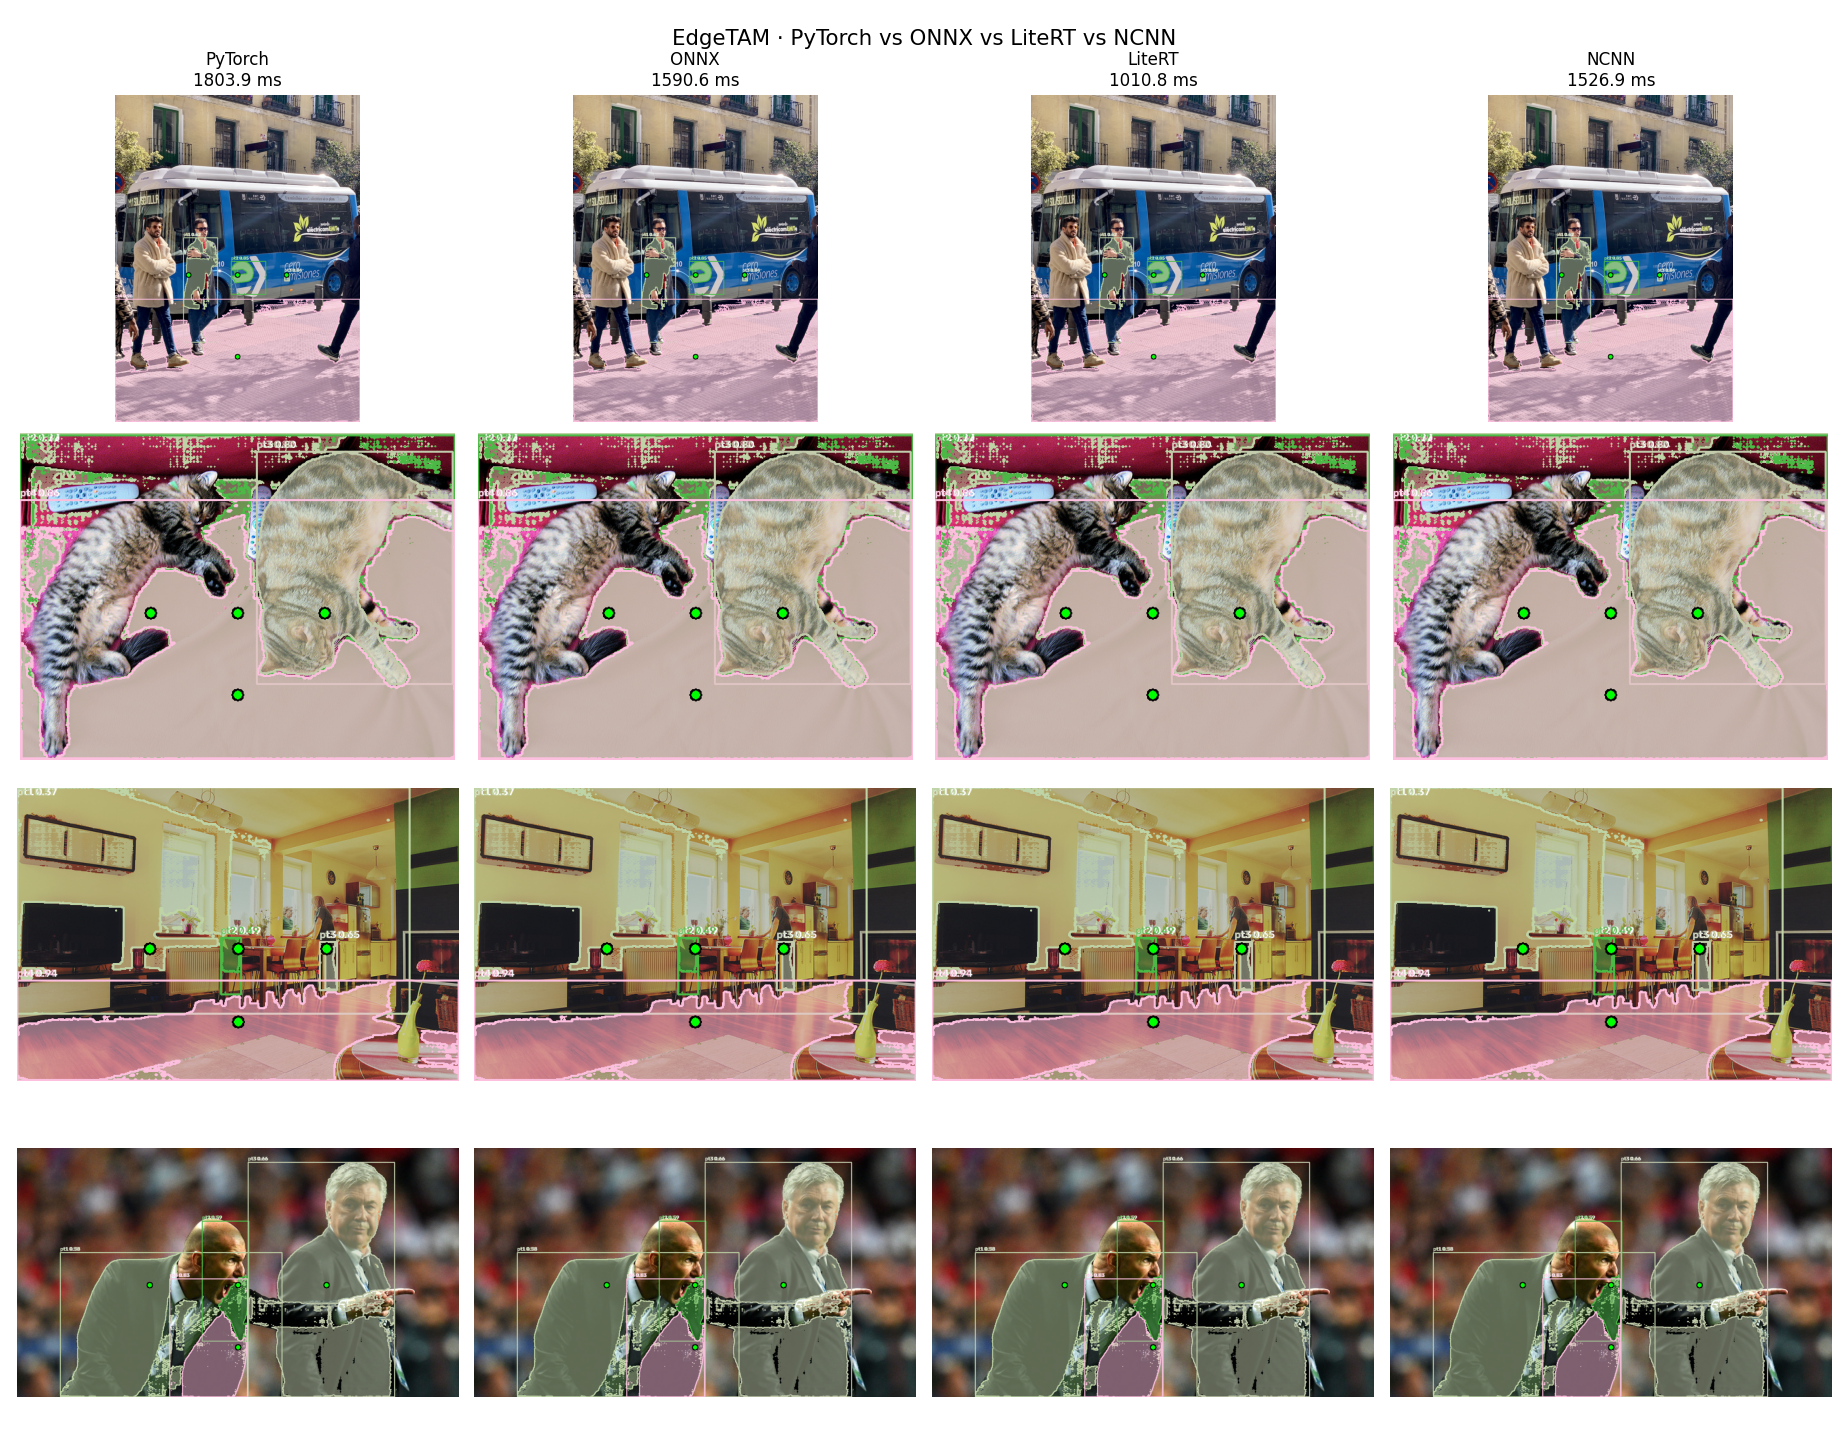


=== SUMMARY ===
{
 "PyTorch": {
  "status": "ok",
  "ms": 1803.9,
  "instances": [
   4,
   4,
   4,
   4
  ]
 },
 "ONNX": {
  "status": "ok",
  "ms": 1590.6,
  "instances": [
   4,
   4,
   4,
   4
  ],
  "max_abs_diff_vs_ref": 0.00025177001953125,
  "max_rel_diff": 3.069152853640844e-06
 },
 "LiteRT": {
  "status": "ok",
  "ms": 1010.8,
  "instances": [
   4,
   4,
   4,
   4
  ],
  "max_abs_diff_vs_ref": 0.00035858154296875,
  "max_rel_diff": 4.371217528387206e-06
 },
 "NCNN": {
  "status": "ok",
  "ms": 1526.9,
  "instances": [
   4,
   4,
   4,
   4
  ],
  "max_abs_diff_vs_ref": 0.11069488525390625,
  "max_rel_diff": 0.0013494041049852967
 }
}
model files (MB): {'edgetam_decoder.ncnn.bin': 24.63, 'edgetam_decoder.ncnn.param': 0.01, 'edgetam_decoder.onnx': 16.38, 'edgetam_decoder.tflite': 20.63, 'edgetam_encoder.ncnn.bin': 19.6, 'edgetam_encoder.ncnn.param': 0.03, 'edgetam_encoder.onnx': 19.75, 'edgetam_encoder.tflite': 20.04}
ZIP: /content/edgetam_export_bundle.zip (114.1 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
save_grid("EdgeTAM · PyTorch vs ONNX vs LiteRT vs NCNN")
zip_path = finish("edgetam")